# Second meeting: tuned lens vs logit lens

Copy of `layerwise_decoding.ipynb` (first meeting) with one addition: the per-layer decoding is repeated with a
**tuned lens** (Belrose et al., 2023, "Eliciting Latent Predictions from Transformers with the Tuned Lens"),
trained here on generic text, and compared with the logit lens. Everything above "Per-Layer Decoding" is unchanged.

**Run order:** as before (skip the switch and valid/invalid model passes if short on time), then the tuned-lens
training cells (~1–1.5 h on a T4 the first time; reloaded afterwards), then the lens cells (~46 min per grammar,
giving both lenses in one pass).


# Computation or Weight Adaptation? Rethinking the role of plasticity in learning

Welcome to Our Notebook! 🚀  

To get started, you'll need to add your Hugging Face (HF) token to load the model. Follow these steps to securely add your token as a secret in your notebook:  

1. In the left sidebar, click on the **key icon**.  
2. Select **"Add new secret"**.  
3. Set the name to **`HF_token`**.  
4. Paste your Hugging Face access token as the value.  

If you don’t have an access token yet, you can generate one by following the instructions [here](https://huggingface.co/docs/hub/en/security-tokens).  


Below is a screenshot of how it should look like:


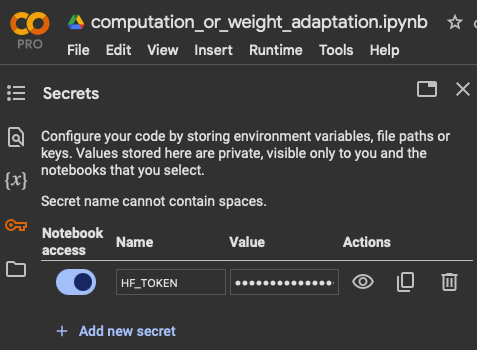

### Once your token is added, you're all set to run this notebook! 🚀

In [ ]:
!pip install --upgrade spacy
!pip install -q -U bitsandbytes
!pip install -q datasets  # tuned-lens training text
!python -m spacy download en_core_web_trf


## Import packages

In [ ]:
import json
import random
from tqdm import tqdm
import spacy
random.seed(42)

## Set run parameters

In [ ]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
LOAD_IN_8BIT_ON_CUDA = True  # set False if your GPU has enough memory for full float16 (e.g. A100/L4); needed on a free-tier T4 (14.5GB) to avoid OOM
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [ ]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [ ]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

In [ ]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

In [ ]:
agl_transitions_other = {

}

## Generate Sequences

In [ ]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [ ]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [ ]:
def build_random_DFA(vocab):
  vocab_copy = vocab.copy()
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [ ]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [ ]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [ ]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### Run Sequence Generation

In [ ]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

In [ ]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]
switch_vocab = []
for i in range(len(all_placeholder_prompts)):
  shuffle_vocab_words = shuffle_vocab[i]
  vocab_reduced = [w for w in tokens_list if w not in shuffle_vocab_words]
  vocab_for_switch = random.sample(vocab_reduced, k=vocab_length)
  switch_vocab.append(shuffle_vocab_words + vocab_for_switch)

run_modes = ["shuffle", "switch"]
output = {k: [] for k in run_modes}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  for mode in run_modes:
    output[mode].append(prompt_dict.copy())
    if mode == 'shuffle':
      vocab = shuffle_vocab[i]
      mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
    else:  # mode == 'switch'
      vocab = switch_vocab[i]
      first_vocab = vocab[:len(vocab)//2]
      second_vocab = vocab[len(vocab)//2:]
      mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], first_vocab), map_prompt(
          prompt_dict["placeholder_prompt"], second_vocab)
      indices = [i for i in range(len(mapped_prompt[0])) if mapped_prompt[1][i] == SEP_TOKEN]
      middle_index = indices[len(indices) // 2]
      mapped_prompt = mapped_prompt[0][:middle_index] + mapped_prompt[1][middle_index:]
      output[mode][-1]["switch_index"] = middle_index
    output[mode][-1]["mapped_prompt"] = mapped_prompt
    output[mode][-1]["vocab"] = vocab

# Predict Probabilities

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [ ]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [ ]:
import logging
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)  # silences repeated per-matmul cast-precision
                                                              # logging noise from the 8-bit quantized model;
                                                              # purely cosmetic, no effect on results

In [ ]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  if device == 'cuda' and LOAD_IN_8BIT_ON_CUDA:
    from transformers import BitsAndBytesConfig
    quantization_config = BitsAndBytesConfig(load_in_8bit=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, quantization_config=quantization_config, low_cpu_mem_usage=True)
  else:
    dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [ ]:
def calculate_next_token_probs(model, tokenizer, input_sequence, vocab_by_order):
  """
  given a list of tokens, referred as input_sequence, calculates next token probabilities.
  :param model: the model to use for calculating the probabilities
  :param tokenizer: the tokenizer to use for tokenizing the input sequence
  :param input_sequence: the sequence to calculate logits on
  :param vocab_by_order: the vocabulary by order of appearance in the prompt
  :return: the next token logits (or probabilities) for any of the tokens in the sequence.
  """

  # handle words that tokenized to more than 2 tokens
  new_vocab = []
  one_token_mapping = {SEP_TOKEN: SEP_TOKEN}
  for i, word in enumerate(vocab_by_order):
    ids = tokenizer.encode(word, return_tensors='pt')
    first_token = tokenizer.decode(ids[0, 1]) # if running llama model, should be 0, 1, if gpt then 0,0
    one_token_mapping[word] = first_token
    new_vocab.append(first_token)
  vocab_by_order = new_vocab
  input_sequence = [one_token_mapping[w] for w in input_sequence]

  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)
  uniques = input_ids.unique()
  mapping = {tokenizer.decode(token_id).strip(): {'input_id': token_id.item()} for token_id in uniques}
  if SEP_TOKEN in mapping:
    vocab_by_order.append(SEP_TOKEN)
  token_ids_sequence = [mapping[token.strip()]["input_id"] for token in vocab_by_order]
  for token in vocab_by_order:
    mapping[token.strip()]["probs_index"] = token_ids_sequence.index(mapping[token.strip()]["input_id"])

  # Generate logits for each token in the input
  with torch.no_grad():
    device = get_device()
    logits = model(input_ids=input_ids.to(device))[0]

  logits = torch.softmax(logits, dim=-1)
  logits = logits.squeeze()
  input_ids = input_ids.squeeze()

  # get the top 10 tokens in each step
  top_10_tokens = torch.topk(logits, 10, dim=-1)

  # retrieves the logits of the input tokens only
  next_token_prediction = logits[:, token_ids_sequence]

  # Define loss function
  criterion = torch.nn.CrossEntropyLoss(reduction='none')  # reduction='none' to get loss per item

  losses = criterion(logits.view(-1, logits.size(-1)).to(device), input_ids.view(-1).to(device))

  cumulative_sum = losses.cumsum(dim=0)
  index_tensor = torch.arange(1, len(losses) + 1)
  losses_mean = cumulative_sum / index_tensor.to(device)

  return next_token_prediction, mapping, token_ids_sequence, top_10_tokens, losses_mean.tolist()

In [ ]:
def get_probabilities(model, tokenizer, all_prompts):
  output_dicts = []
  for prompt_dict in tqdm(all_prompts):
    sequence_for_predict = prompt_dict["mapped_prompt"]
    vocab_by_order = prompt_dict["vocab"]
    if type(vocab_by_order[0]) == list:
      vocab_by_order = [item for sublist in vocab_by_order for item in sublist]
    next_token_prediction, mapping, token_ids_sequence, top_k, lm_losses = calculate_next_token_probs(
      model, tokenizer, sequence_for_predict, vocab_by_order)
    prompt_dict["next_token_prediction"] = next_token_prediction.tolist()
    prompt_dict["mapping"] = mapping
    prompt_dict["token_ids_sequence"] = token_ids_sequence
    prompt_dict["lm_losses"] = lm_losses
    prompt_dict["top_k_indices"] = top_k.indices.tolist()
    prompt_dict["top_k_values"] = top_k.values.tolist()
    output_dicts.append(prompt_dict)
  return output_dicts

In [ ]:
def get_states_probabilities(prompt_dict):
  learning_starts = prompt_dict["learning_begins"]
  learning_ends = prompt_dict["learning_ends"]
  transitions = prompt_dict['next_token_prediction'][learning_starts:learning_ends]
  states = prompt_dict['structure_state_sequences']
  vocab_len = len(prompt_dict["vocab"])
  if SEP_TOKEN not in prompt_dict["vocab"]:
    vocab_len += 1
  transitions_by_state = {}
  for i, state in enumerate(states):
    if state not in transitions_by_state:
      transitions_by_state[state] = np.array([]).reshape(0, vocab_len)
    transitions_by_state[state] = np.vstack([transitions_by_state[state], transitions[i]])
  return transitions_by_state

In [ ]:
def get_states_gold_probabilities(prompt_dict, states):
  learning_starts = prompt_dict["learning_begins"]
  learning_ends = prompt_dict["learning_ends"]
  transitions = prompt_dict['transition_probabilities'][learning_starts:learning_ends]
  structure_state_sequences = prompt_dict['structure_state_sequences']
  transitions_by_state = {}
  for i, state in enumerate(structure_state_sequences):
    if state not in transitions_by_state:
      transitions_by_state[state] = transitions[i]
    if set(transitions_by_state.keys()) == set(states):
      return transitions_by_state
  else:
    raise ValueError("missing gold state probabilities")

In [ ]:
def get_gold_probabilities(prompt_dict):
  prompt = prompt_dict["mapped_prompt"]
  gold_label_probabilities = []
  total_vocab_lst = prompt_dict["vocab"]
  for i in range(len(prompt)):
    prob = prompt_dict["transition_probabilities"][i]
    token = prompt[i]
    if token == SEP_TOKEN:
      dict_key = SEP_TOKEN
    else:
      if "switch_index" in prompt_dict:  # run in switch mode
        if i < prompt_dict["switch_index"]:
          vocab_lst = total_vocab_lst[:len(total_vocab_lst)//2]
        else:
          vocab_lst = total_vocab_lst[len(total_vocab_lst)//2:]
      else:
        vocab_lst = total_vocab_lst
      dict_key = str(vocab_lst.index(token))
    gold_label_probabilities.append(prob[dict_key])
  return gold_label_probabilities

In [ ]:
def get_next_token_probabilities(prompt_dict):
  next_token_prediction = np.array(prompt_dict["next_token_prediction"])
  mapping = prompt_dict["mapping"]
  prompt = prompt_dict["mapped_prompt"]
  if "" in prompt:
    print("ERROR")
  unique_tokens = set(prompt)
  map_tokens = {}
  # get all possible couples between two lists
  for couple in product(unique_tokens, mapping.keys()):
    if couple[0].startswith(couple[1]):
      map_tokens[couple[0]] = couple[1]
  map_tokens[SEP_TOKEN] = SEP_TOKEN
  prompt = [map_tokens[str(token)] for token in prompt]
  if prompt != prompt_dict["mapped_prompt"]:
    prompt_dict["mapped_prompt"] = prompt
    prompt_dict["vocab"] = [map_tokens[str(token)] for token in prompt_dict["vocab"]]
    if SEP_TOKEN not in prompt_dict["vocab"]:
      prompt_dict["vocab"].append(SEP_TOKEN)
  index_list = [mapping[str(token)]["probs_index"] for token in prompt]
  # next_token_prediction_only_prompt = next_token_prediction[np.arange(len(next_token_prediction)-1), index_list[1:]]
  next_token_prediction_only_prompt = next_token_prediction[np.arange(len(next_token_prediction)-1), index_list]
  return next_token_prediction_only_prompt

### Load model from HuggingFace

In [ ]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


### Run probabilities prediction

In [ ]:
shuffle_seq_outputs = get_probabilities(model, tokenizer, output["shuffle"])

# Generate plots

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    'axes.labelsize': 14,  # Axis labels
    'xtick.labelsize': 14,  # X-axis tick labels
    'ytick.labelsize': 14   # Y-axis tick labels
})

In [ ]:
def plot_predictions(learning_ends, learning_starts, predictions, si=None):
  plt.plot(predictions[:learning_starts], color='blue')
  if si is not None:
    plt.fill_between(np.arange(0, learning_starts),
                      predictions[:learning_starts] - si[:learning_starts],
                      predictions[:learning_starts] + si[:learning_starts],
                      alpha=0.5, color="blue")
  if learning_ends != -1:
    plt.plot(np.arange(learning_starts, learning_ends), predictions[learning_starts:learning_ends],
              label='Learning predictions', color='orange')
    plt.plot(np.arange(learning_ends, len(predictions)), predictions[learning_ends:], color='blue')
    if si is not None:
      plt.fill_between(np.arange(learning_starts, learning_ends),
                        predictions[learning_starts:learning_ends] - si[learning_starts:learning_ends],
                        predictions[learning_starts:learning_ends] + si[learning_starts:learning_ends],
                        alpha=0.5, color="orange")
      plt.fill_between(np.arange(learning_ends, len(predictions)),
                        predictions[learning_ends:] - si[learning_ends:],
                        predictions[learning_ends:] + si[learning_ends:],
                        alpha=0.5, color="blue")
  else:
    plt.plot(np.arange(learning_starts, len(predictions)), predictions[learning_starts:],
              label='Learning predictions', color='orange')
    if si is not None:
      plt.fill_between(np.arange(learning_starts, len(predictions)),
                        predictions[learning_starts:] - si[learning_starts:],
                        predictions[learning_starts:] + si[learning_starts:],
                        alpha=0.5, color="orange")


def plot_labels(labels, learning_ends, learning_starts):
  if learning_ends != -1:
    plt.plot(np.arange(learning_starts, learning_ends),
              np.full((learning_ends-learning_starts,), fill_value=np.average(labels[learning_starts:learning_ends])),
              linestyle='dashed', color='black', alpha=0.8, label='theoretical upper bound for next token prob')
  else:
    plt.plot(np.arange(learning_starts, len(labels)),
              np.full((len(labels)-learning_starts,), fill_value=np.average(labels[learning_starts:])),
              linestyle='dashed', color='black', alpha=0.8,  label='theoretical upper bound for next token prob')
  plt.legend()

def plot_next_token_probabilities(predictions, learning_starts, learning_ends, labels=None, si=None):
  plt.rcParams["figure.figsize"] = (11, 5)
  plt.figure()
  plot_predictions(learning_ends, learning_starts, predictions, si=si)
  if labels is not None:
    plot_labels(labels, learning_ends, learning_starts)
  plt.xlabel("Iteration")
  plt.ylabel("Probability")
  plt.show()

In [ ]:
all_next_token_probabilities_predictions = []
gold_all_next_token_probabilities = []
all_states_probabilities = []
learning_indices = {"start": [], "end": [], "length": [], "sequence_learning_iterations": []}
prefix_length = random_epochs
for prompt_dict in tqdm(shuffle_seq_outputs):
  learning_indices["start"].append(prompt_dict["learning_begins"])
  learning_indices["end"].append(len(prompt_dict["mapped_prompt"]) - prompt_dict["learning_ends"])
  learning_indices["length"].append(prompt_dict["learning_ends"] - prompt_dict["learning_begins"])
  learning_indices["sequence_learning_iterations"].append(prompt_dict["learning_epochs"])
  next_token_pred = get_next_token_probabilities(prompt_dict)
  gold_token_prob = get_gold_probabilities(prompt_dict)
  all_next_token_probabilities_predictions.append(next_token_pred)
  gold_all_next_token_probabilities.append(gold_token_prob)
  states_probabilities = get_states_probabilities(prompt_dict)
  all_states_probabilities.append(states_probabilities)

state_gold_probabilities = get_states_gold_probabilities(shuffle_seq_outputs[0], all_states_probabilities[0].keys())

min_start = min(learning_indices["start"])
max_start = max(learning_indices["start"])
min_length = min(learning_indices["length"])
min_end = min(learning_indices["end"])
min_sequence_learning_iterations = min(learning_indices["sequence_learning_iterations"])

def trim(sequence, learning_idx):
  start = sequence[:min_start]
  learning = sequence[learning_idx:learning_idx + min_length]
  if min_end > 0:
    end = sequence[-min_end:]
  else:
    end = []
  return np.concatenate((start, learning, end))

trimmed_token_probabilities = []
trimmed_gold_token_probabilities = []
for i in range(len(all_next_token_probabilities_predictions)):
  learning_begins = learning_indices["start"][i]
  trimmed_token_probabilities.append(trim(all_next_token_probabilities_predictions[i], learning_begins))
  trimmed_gold_token_probabilities.append(trim(gold_all_next_token_probabilities[i], learning_begins))

In [ ]:
# new_trimed = []
# for i in range(len(trimmed_token_probabilities)):
#   if len(trimmed_token_probabilities[i]) == 668:
#     new_trimed.append(trimmed_token_probabilities[i])
# print(len(new_trimed))

In [ ]:
mean_token_probabilities = np.mean(np.array(trimmed_token_probabilities), axis=0)
si_token_probabilities = (np.std(np.array(trimmed_token_probabilities), axis=0) / 10)
mean_token_gold = np.mean(np.array(trimmed_gold_token_probabilities), axis=0)  # gold (DFA) probs, not predictions

In [ ]:
print(f"The experiment includes {len(mean_token_probabilities)}, in which {min_start} random tokens for {random_epochs} sequences, and {len(mean_token_probabilities)-min_end-min_start} tokens for {learning_epochs} sequences, followed by {min_end} random tokens again.")

### Plot mean next token probabilities

In [ ]:
plot_next_token_probabilities(mean_token_probabilities, labels=mean_token_gold, learning_starts=min_start,
                              learning_ends=min_start+min_length, si=si_token_probabilities)


## Each state probabilities

In [ ]:
def get_mean_state_probabilities(all_states_probabilities, max_size):
  mean_state_probabilities = {}
  std_state_probabilities = {}
  for state in all_states_probabilities[0]:
    mean_state_probabilities[state] = np.full((len(all_states_probabilities), max_size,
                                                all_states_probabilities[0][state].shape[1]), np.nan)

    for i in range(len(all_states_probabilities)):
      mean_state_probabilities[state][i][:all_states_probabilities[i][state].shape[0]] = all_states_probabilities[i][state]
    mutual_min = min(all_states_probabilities[i][state].shape[0] for i in range(len(all_states_probabilities)))
    mean_state_probabilities[state] = mean_state_probabilities[state][:, :mutual_min, :]
    std_state_probabilities[state] = np.nanstd(mean_state_probabilities[state], axis=0) / 10
    mean_state_probabilities[state] = np.nanmean(mean_state_probabilities[state], axis=0)
  return mean_state_probabilities, std_state_probabilities

In [ ]:
mean_state_probabilities, std_state_prob = get_mean_state_probabilities(all_states_probabilities,
                                                                        len(shuffle_seq_outputs[0]["next_token_prediction"]))

for state in mean_state_probabilities:
  plt.figure()
  for i in range(mean_state_probabilities[state].shape[1]):
    if i == mean_state_probabilities[state].shape[1] - 1:
      placeholder = SEP_TOKEN
    else:
      placeholder = str(i)
    line, = plt.plot(mean_state_probabilities[state][:, i], label=f'{placeholder}: {state_gold_probabilities[state].get(placeholder, 0):.2f}')
    if std_state_prob is not None:
      plt.fill_between(np.arange(len(mean_state_probabilities[state][:, i])),
                        mean_state_probabilities[state][:, i] - std_state_prob[state][:, i],
                        mean_state_probabilities[state][:, i] + std_state_prob[state][:, i],
                        alpha=0.5, color=line.get_color())
  plt.legend()
  plt.xlabel(f"Index of traversing through {state}")
  if RANDOM_WEIGHTS:
    plt.ylim(0,0.0001)
  plt.ylabel("Probability")
  plt.show()

## Predictions hist

In [ ]:
batch_size = 100
only_structured_preds = np.array(trimmed_token_probabilities)[:, max_start:-min_end]
only_structured_gold = np.array(trimmed_gold_token_probabilities)[:, max_start:-min_end]
num_batches = (len(only_structured_gold[0]) // batch_size)
for i in range(num_batches):
  plt.figure(f"hist batch {i}")
  start = i*batch_size
  end = (i+1)*batch_size
  unique_golds = np.unique(only_structured_gold[0])
  colors = ['b', 'g', 'r', 'c']
  dict_for_hist = {}
  for i, gold_val in enumerate(unique_golds):
    if gold_val in {0.2, 0.25}:  # skip random
      print(gold_val)
      continue
    all_preds_for_gold = []
    batch_gold = only_structured_gold[:, start:end]
    batch_pred = only_structured_preds[:, start:end]
    for j in range(len(only_structured_gold)):
      gold_indices = np.where(gold_val == batch_gold[j])[0]
      pred_for_gold = np.array(batch_pred[j])[gold_indices]
      all_preds_for_gold.extend(pred_for_gold)
    if gold_val == 1/3:
      gold_val = 0.33
    dict_for_hist[gold_val] = all_preds_for_gold

  for i, gold_val in enumerate(dict_for_hist):
    pred_for_gold = dict_for_hist[gold_val]
    plt.hist(pred_for_gold, bins=50, color=colors[i], alpha=0.5, label=f"{gold_val}", density=True)

  plt.legend()
  plt.title(f"Predicted probability in iteration {start} to {end}")
  plt.xlabel("Predicted Probability")
  plt.ylabel("Frequency")
  plt.show()

## Distribution of probablities random vs structured

In [ ]:
random_prefix = []
random_suffix = []
structured_all = []
for j in range(len(all_next_token_probabilities_predictions)):
  random_start = all_next_token_probabilities_predictions[j][:learning_indices['start'][j]]
  random_prefix.extend(random_start)
  structured = all_next_token_probabilities_predictions[j][learning_indices['start'][j]:-learning_indices['end'][j]]
  structured_all.extend(structured)
  random_end = all_next_token_probabilities_predictions[j][-learning_indices['end'][j]:]
  random_suffix.extend(random_end)
plt.violinplot([random_prefix, structured_all, random_suffix], showmeans=True)
plt.xticks([1,2,3], ['baseline', 'structured', 'post-learning'])
plt.ylabel('next-token probability')
plt.show()

# Switch vocabulary

In [ ]:
switch_seq_outputs = get_probabilities(model, tokenizer, output["switch"])

In [ ]:
import pandas as pd
from scipy.stats import ttest_ind, ttest_rel

In [ ]:
switch_all_next_token_probabilities_predictions = []
switch_indices = []
start_indices = []
for prompt_dict in tqdm(switch_seq_outputs):
  switch_indices.append(prompt_dict.get("switch_index", -1)+1)
  start_indices.append(prompt_dict["learning_begins"])
  next_token_pred = get_next_token_probabilities(prompt_dict)
  switch_all_next_token_probabilities_predictions.append(next_token_pred)

min_switch_index = min(switch_indices)
half_min_len = min([switch_indices[i]-start_indices[i] for i in range(len(start_indices))])

def trim_first_half(sequence, learning_idx):
  start = sequence[:min_start]
  first_half_learning = sequence[learning_idx:][:half_min_len]
  return np.concatenate((start, first_half_learning))

def trim_after_switch(sequence, switch_idx):
  end = []
  if min_end > 0:
    end = sequence[-min_end:]
  second_half_learning = sequence[switch_idx:][:half_min_len]
  return np.concatenate((second_half_learning, end))

before_switch = []
after_switch = []
for i in range(len(switch_all_next_token_probabilities_predictions)):
  learning_begins = start_indices[i]
  switch_index = switch_indices[i]
  before_switch.append(trim_first_half(switch_all_next_token_probabilities_predictions[i], learning_begins))
  after_switch.append(trim_after_switch(switch_all_next_token_probabilities_predictions[i], switch_index))

In [ ]:
switch_mean_before_switch = np.mean(np.array(before_switch), axis=0)
switch_si_before_switch = np.std(np.array(before_switch), axis=0) / 10

switch_mean_after_switch = np.mean(np.array(after_switch), axis=0)
switch_si_after_switch = np.std(np.array(after_switch), axis=0) / 10

In [ ]:
def plot_switch(switch_mean_before_switch, switch_si_before_switch, switch_mean_after_switch, switch_si_after_switch):
  fig, ax = plt.subplots()

  window_size = 7  # Adjust this based on your preferences
  smoothed_until = pd.Series(switch_mean_before_switch).rolling(window=window_size).mean()[window_size-1:]
  smoothed_after = pd.Series(switch_mean_after_switch).rolling(window=window_size).mean()[window_size-1:]
  bottom_ax = np.arange(0, len(switch_mean_before_switch)+min_end-(window_size-1))

  plt.plot(smoothed_until, color='darkcyan', label='Before')
  plt.plot(bottom_ax[min_start:], smoothed_after, color='purple', label='After')
  if min_end != 0:
    _, pval = ttest_rel(smoothed_until[min_start:], smoothed_after[:-min_end])
  else:
      _, pval = ttest_rel(smoothed_until, smoothed_after)
  if pval < 0.01:
      if round(pval, 5) == 0.0:
          str_p = "< 0.00001"
      else:
          str_p = f"= {round(pval, 5)}"
      plt.text(500, 0.45, f"* p {str_p}", fontdict={'size': 12, 'color': 'purple' if np.mean(smoothed_until) < np.mean(smoothed_after) else 'darkcyan'})
  else:
      str_p = f"= {round(pval, 5)}"
      plt.text(500, 0.45, f"p {str_p}", fontdict={'size': 12, 'color': 'black'})
  print(f"mean before = {round(np.mean(smoothed_until[min_start:]), 3)}, after = {round(np.mean(smoothed_after[:-min_end]),3)}",  )

  plt.axhline(y=0, color='darkcyan')
  for i in range(7):
      jump = i*250
      plt.text(jump, 0, f"|", fontdict={'size': 7, 'color': 'darkcyan'}, )
      plt.text(jump-25, -0.021, f"{jump}", fontdict={'size': 14, 'color': 'darkcyan'})

  plt.ylabel("Probability")
  plt.xlabel("Iteration")
  plt.tick_params(axis='x', color='purple', labelcolor='purple')
  first_x_label = len(smoothed_until) + 250 - (len(smoothed_until) % 250)
  first_x_coord = min_start + 250 - (len(smoothed_until) % 250)
  max_x_xoord = min_start + len(smoothed_until) - (len(smoothed_until) % 250)
  ticks = np.arange(first_x_coord, max_x_xoord+1, 250)
  labels = []
  for i in range(len(ticks)):
    labels.append(f"{i*250+first_x_label}")
  plt.xticks(np.concatenate(([min_start], ticks)), np.concatenate(([len(smoothed_until)], labels)))
  ax.spines.bottom.set_color('purple')
  plt.ylim(-0.03, plt.ylim()[1])
  plt.legend()
  plt.show()

In [ ]:
plot_switch(switch_mean_before_switch, switch_si_before_switch, switch_mean_after_switch, switch_si_after_switch)

## Control with two-tokens switch

For each valid sequence, we switch two random consecutive tokens, and check how robabilities chage

In [ ]:
def get_all_unique_sequences(prompt_dict):
  learning_ends = prompt_dict["learning_ends"]
  learning_begins = prompt_dict["learning_begins"]
  structured_part = prompt_dict["mapped_prompt"][learning_begins:learning_ends]
  all_valid_sequences = ' '.join(structured_part).split(SEP_TOKEN)
  all_valid_sequences = [seq.strip() for seq in all_valid_sequences if seq.strip() != '']
  all_valid_sequences = sorted(list(set(all_valid_sequences)))
  valid_seq_as_list = [seq.split(' ') for seq in all_valid_sequences]
  return valid_seq_as_list

In [ ]:
def switch_two_letters(sequence):
  copy_sequence = sequence.copy()
  if len(sequence) > 2:
    random_i = random.randint(1, len(sequence)-2)
  else:
    random_i = 0
  copy_sequence[random_i], copy_sequence[random_i+1] = sequence[random_i+1], sequence[random_i]
  new_seq = " ".join(copy_sequence)
  return new_seq, random_i

output["valid"] = []
output["invalid"] = []

from copy import deepcopy

for prompt_dict in tqdm(output["shuffle"]):
  new_prompt_dict = {}
  valid_seq_as_list = get_all_unique_sequences(prompt_dict)
  random.shuffle(valid_seq_as_list)
  half_index = len(valid_seq_as_list) // 2
  valid_first_half = valid_seq_as_list[:half_index]
  valid_second_half = valid_seq_as_list[half_index:]
  invalid_seq = [switch_two_letters(seq) for seq in valid_second_half]
  sequences = [seq[0] for seq in invalid_seq]
  indices = [seq[1] for seq in invalid_seq]
  for i in range(len(valid_second_half)):
    assert sequences[i].split(' ')[indices[i]] != valid_second_half[i][indices[i]] or valid_second_half[i][indices[i]] == valid_second_half[i][indices[i]+1]
  valid_sequences_as_str = [' '.join(seq) for seq in valid_first_half]
  valid_sequences = f" {SEP_TOKEN} ".join(valid_sequences_as_str).split(' ')
  invalid_sequences = f" {SEP_TOKEN} ".join(sequences).split(' ')
  new_prompt_dict["switch_index"] = len(valid_sequences)+1
  all_prompt_list = valid_sequences + [SEP_TOKEN] + invalid_sequences
  new_prompt_dict["mapped_prompt"] = all_prompt_list
  new_prompt_dict["learning_begins"] = 0
  new_prompt_dict["learning_ends"] = len(all_prompt_list)
  new_prompt_dict["vocab"] = prompt_dict["vocab"]
  new_prompt_dict["learning_epochs"] = len(valid_seq_as_list)
  all_first_tokens = [new_prompt_dict["switch_index"]]
  for i, token in enumerate(invalid_sequences):
    if token == SEP_TOKEN:
      all_first_tokens.append(i+new_prompt_dict["switch_index"]+1)
      assert new_prompt_dict["mapped_prompt"][all_first_tokens[-1]-1] == SEP_TOKEN
  to_plot = []
  for i, first_token in enumerate(all_first_tokens):
    to_plot.append(first_token+indices[i])
  new_prompt_dict["indices_to_plot"] = to_plot
  assert(min(to_plot) >= new_prompt_dict["switch_index"])
  output["invalid"].append(new_prompt_dict)
  second_half_valid = [' '.join(seq) for seq in valid_seq_as_list[half_index:]]
  valid_sequences_second_half = f" {SEP_TOKEN} ".join(second_half_valid).split(' ')
  output["valid"].append(new_prompt_dict.copy())
  output["valid"][-1]["mapped_prompt"] = valid_sequences + [SEP_TOKEN] + valid_sequences_second_half
  assert (output["invalid"][-1]["mapped_prompt"] != output["valid"][-1]["mapped_prompt"])

In [ ]:
valid_probs = get_probabilities(model, tokenizer, output["valid"])
invalid_probs = get_probabilities(model, tokenizer, output["invalid"])

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

all_valid = []
half_invalid = []
begining = []
all_valid_total = []
all_invalid_total = []
for prompt_dict in valid_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  indices = np.array(prompt_dict["indices_to_plot"])
  all_valid.append(next_token_probability_predictions[indices])
  begining.append(next_token_probability_predictions[:prompt_dict["switch_index"]])
  all_valid_total.append(next_token_probability_predictions)
for prompt_dict in invalid_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  indices = np.array(prompt_dict["indices_to_plot"])
  half_invalid.append(next_token_probability_predictions[indices])
  all_invalid_total.append(next_token_probability_predictions)

min_num_seqs = min(len(valid) for valid in all_valid)
min_training_len = min(len(valid) for valid in begining)
all_valid = [val[:min_num_seqs] for val in all_valid]
half_invalid = [inval[:min_num_seqs] for inval in half_invalid]
all_valid_total_min = min(len(valid) for valid in all_valid_total)
all_valid_total = [val[:all_valid_total_min] for val in all_valid_total]
all_invalid_total = [val[:all_valid_total_min] for val in all_invalid_total]
begining = [val[:min_training_len] for val in begining]
mean_all_begining = np.mean(np.array(begining), axis=0)
mean_all_valid = np.mean(np.array(all_valid), axis=0)
mean_half_invalid = np.mean(np.array(half_invalid), axis=0)
mean_all_valid_total = np.mean(np.array(all_valid_total), axis=0)
mean_all_invalid_total = np.mean(np.array(all_invalid_total), axis=0)

t_stat, pval = ttest_ind(mean_all_valid_total, mean_all_invalid_total, equal_var=False)

if round(pval, 5) == 0.0:
    str_p = "< 0.00001"
else:
    str_p = f"= {round(pval, 5)}"
plt.text(1100, 0.46, f"* p {str_p}", fontdict={'size': 12, 'color': 'green', 'alpha': 0.7})
print(f"mean valid cont. = {round(np.mean(mean_all_valid_total), 3)}, invalid cont. = {round(np.mean(mean_all_invalid_total),3)}")

plt.plot(mean_all_begining, label='training')
x_axis = np.arange(len(mean_all_begining),len(mean_all_valid_total))
plt.plot(x_axis, mean_all_valid_total[len(mean_all_begining):], label='valid cont.', alpha=0.5, color="green")
plt.plot(x_axis, mean_all_invalid_total[len(mean_all_begining):], label='invalid cont.', alpha=0.5, color="red")
plt.ylabel("Probability")
plt.xlabel("Iteration")
plt.legend(fontsize=12)
plt.show()

In [ ]:
print(t_stat, pval)

## SRTT experiments

In [ ]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [ ]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [ ]:
# NOTE: all SRTT runs share ONE generated sequence (including the random baseline/post segments);
# only the vocabulary differs between runs, so averaging over runs averages over vocabularies,
# not over random sequences. (The SRTT cells below also assume equal-length runs.)
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]


In [ ]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

In [ ]:
srtt_probs = get_probabilities(model, tokenizer, output_srtt)

In [ ]:
srtt_results = []
for prompt_dict in srtt_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  start_index = prompt_dict["learning_begins"]
  end_index = prompt_dict["learning_ends"]
  srtt_results.append(next_token_probability_predictions)
mean_token_probabilities_srtt = np.mean(np.array(srtt_results), axis=0)
si_token_probabilities_srtt = (np.std(np.array(srtt_results), axis=0) / 10)
labels = [1]*(end_index-start_index)

In [ ]:
plot_next_token_probabilities(mean_token_probabilities_srtt, labels=labels, learning_starts=start_index,
                              learning_ends=end_index, si=si_token_probabilities_srtt)

In [ ]:
one_single_prompt = srtt_probs[0]
start_index = one_single_prompt["learning_begins"]
end_index = one_single_prompt["learning_ends"]
total_len = len(one_single_prompt["mapped_prompt"])
print(f"For SRTT, we show a total of {srtt_random_epochs}, in total it is {start_index} tokens.")
print(f"Then, we show {srtt_learning_epochs}, total of {end_index-start_index} tokens.")
print(f"Last, is again {srtt_random_epochs}, total of {total_len-end_index} tokens.")
print(f"Each prompt has a vocabulary of {one_single_prompt['vocab']}")

## KL Divergence

In [ ]:
# !pip install --upgrade scipy

In [ ]:
from scipy.special import rel_entr

def calculate_kl_divergence(predicted_probs, true_probs):
    """
    Calculates the KL divergence between predicted and true probabilities.

    Args:
        predicted_probs (np.ndarray): Array of predicted probabilities.
        true_probs (np.ndarray): Array of true probabilities.

    Returns:
        np.ndarray: Array of KL divergence values.
    """
    # Ensure no zero probabilities to avoid issues with log
    predicted_probs[predicted_probs == 0] = 1e-9
    true_probs[true_probs == 0] = 1e-9

    # Normalize probabilities to ensure they sum to 1
    predicted_probs = predicted_probs / predicted_probs.sum(axis=-1, keepdims=True)
    true_probs = true_probs / true_probs.sum(axis=-1, keepdims=True)

    kl = np.sum(rel_entr(true_probs, predicted_probs[:-1, :]), axis=1)  # computes KL(p || q)

    return kl

def plot_kl_divergence(kl_divergence_values, learning_starts, learning_ends, si=None):
    """
    Plots the KL divergence over iterations.

    Args:
        kl_divergence_values (np.ndarray): Array of KL divergence values.
        learning_starts (int): Index where the learning phase starts.
        learning_ends (int): Index where the learning phase ends.
        si (np.ndarray, optional): Array of standard deviations for shading. Defaults to None.
    """
    plt.figure(figsize=(11, 5))
    plt.plot(kl_divergence_values[:learning_starts], color='blue')
    if si is not None:
      plt.fill_between(np.arange(0, learning_starts),
                        kl_divergence_values[:learning_starts] - si[:learning_starts],
                        kl_divergence_values[:learning_starts] + si[:learning_starts],
                        alpha=0.5, color="blue")

    if learning_ends != -1:
        plt.plot(np.arange(learning_starts, learning_ends), kl_divergence_values[learning_starts:learning_ends],
                 label='Learning Phase', color='orange')
        plt.plot(np.arange(learning_ends, len(kl_divergence_values)), kl_divergence_values[learning_ends:], color='blue')
        if si is not None:
            plt.fill_between(np.arange(learning_starts, learning_ends),
                              kl_divergence_values[learning_starts:learning_ends] - si[learning_starts:learning_ends],
                              kl_divergence_values[learning_starts:learning_ends] + si[learning_starts:learning_ends],
                              alpha=0.5, color="orange")
            plt.fill_between(np.arange(learning_ends, len(kl_divergence_values)),
                              kl_divergence_values[learning_ends:] - si[learning_ends:],
                              kl_divergence_values[learning_ends:] + si[learning_ends:],
                              alpha=0.5, color="blue")

    else:
        plt.plot(np.arange(learning_starts, len(kl_divergence_values)), kl_divergence_values[learning_starts:],
                 label='Learning Phase', color='orange')
        if si is not None:
            plt.fill_between(np.arange(learning_starts, len(kl_divergence_values)),
                              kl_divergence_values[learning_starts:] - si[learning_starts:],
                              kl_divergence_values[learning_starts:] + si[learning_starts:],
                              alpha=0.5, color="orange")


    plt.xlabel("Iteration")
    plt.ylabel("KL Divergence")
    plt.title("KL Divergence between Predicted and True Probabilities")
    plt.legend()
    plt.show()

In [ ]:
shuffle_seq_outputs[0].keys()

In [ ]:
all_kl_divergences = []
for prompt_dict in tqdm(shuffle_seq_outputs):
    predicted_probs = np.array(prompt_dict["next_token_prediction"])
    true_probs_dict = prompt_dict["transition_probabilities"]
    prompt_vocab = prompt_dict["vocab"]

    # Build a matrix of true (DFA) probabilities with the same column order as
    # predicted_probs: one column per vocab word, plus a trailing SEP_TOKEN column.
    # predicted_probs has one extra row (BOS token); calculate_kl_divergence's
    # internal predicted_probs[:-1, :] already accounts for that, so true_probs_dict
    # is used at its natural length here, with no additional trim.
    # prompt_vocab may already contain SEP_TOKEN (appended in place by get_next_token_probabilities
    # for runs with a multi-token word), so count the words explicitly and always append END once.
    num_words = len([w for w in prompt_vocab if w != SEP_TOKEN])
    assert predicted_probs.shape[1] == num_words + 1, (predicted_probs.shape, prompt_vocab)
    aligned_true_probs = []
    for prob_dict in true_probs_dict:
      step_true_probs = [prob_dict.get(str(j), 0.0) for j in range(num_words)]
      step_true_probs.append(prob_dict.get(SEP_TOKEN, 0.0))
      aligned_true_probs.append(step_true_probs)
    aligned_true_probs = np.array(aligned_true_probs)
    assert np.allclose(aligned_true_probs.sum(axis=1), 1.0), "true distribution must sum to 1 at every step"

    kl_values = calculate_kl_divergence(predicted_probs, aligned_true_probs)
    all_kl_divergences.append(kl_values)

# Calculate mean and standard deviation for plotting
min_len_kl = min(len(kl) for kl in all_kl_divergences)
trimmed_kl_divergences = [kl[:min_len_kl] for kl in all_kl_divergences]

mean_kl_divergence = np.mean(np.array(trimmed_kl_divergences), axis=0)
si_kl_divergence = (np.std(np.array(trimmed_kl_divergences), axis=0) / 10) # Assuming 10 iterations for standard error


plot_kl_divergence(mean_kl_divergence, min_start, min_start + min_length, si=si_kl_divergence)

In [ ]:
all_kl_divergences

In [ ]:
from itertools import product

def get_unigram_prior(prompt_dict):
    next_token_prediction = np.array(prompt_dict["next_token_prediction"])
    mapping = prompt_dict["mapping"]
    learning_begins = prompt_dict["learning_begins"]
    baseline_rows = np.arange(0, learning_begins)
    prior = {}
    for token, info in mapping.items():
        col = info["probs_index"]
        prior[token] = (float(np.mean(next_token_prediction[baseline_rows, col]))
                        if len(baseline_rows) > 0 else np.nan)
    return prior

def get_unigram_normalized_next_token_probabilities(prompt_dict, eps=1e-9):
    raw = np.array(get_next_token_probabilities(prompt_dict))
    mapping = prompt_dict["mapping"]
    prompt = prompt_dict["mapped_prompt"]
    unique_tokens = set(prompt)
    map_tokens = {}
    for couple in product(unique_tokens, mapping.keys()):
        if couple[0].startswith(couple[1]):
            map_tokens[couple[0]] = couple[1]
    map_tokens[SEP_TOKEN] = SEP_TOKEN
    norm_prompt = [map_tokens[str(token)] for token in prompt]
    tokens_at_positions = norm_prompt[:len(raw)]
    prior = get_unigram_prior(prompt_dict)
    normalizer = np.array([max(prior.get(t, np.nan), eps) for t in tokens_at_positions])
    return raw / normalizer

In [ ]:
from scipy.stats import ttest_ind, ttest_rel

def cohen_d_independent(a, b):
    a, b = np.asarray(a), np.asarray(b)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na-1)*a.std(ddof=1)**2 + (nb-1)*b.std(ddof=1)**2) / (na+nb-2))
    return (a.mean() - b.mean()) / pooled

def cohen_dz_paired(a, b):
    diff = np.asarray(a) - np.asarray(b)
    return diff.mean() / diff.std(ddof=1)

def report_comparison(a, b, paired, label):
    a, b = np.asarray(a), np.asarray(b)
    if paired:
        t, p = ttest_rel(a, b); d = cohen_dz_paired(a, b); dname = "Cohen's d_z"
    else:
        t, p = ttest_ind(a, b, equal_var=False); d = cohen_d_independent(a, b); dname = "Cohen's d"
    print(f"[{label}]  (n = {len(a)} runs)")
    print(f"    mean(a) = {a.mean():.4f}   mean(b) = {b.mean():.4f}   raw diff = {a.mean()-b.mean():.4f}")
    print(f"    t = {t:.2f}   p = {p:.2e}   {dname} = {d:.2f}\n")
    return d

## Per-Layer Decoding (Logit Lens)

Applies the model's own final norm + LM head to the residual stream after *each* layer
(0 = embeddings, 1..32 = after each transformer block) to ask at which depth the in-context
grammar becomes **readable through the unembedding**. This is not the same as where it is
*computed*: the logit lens is known to under-read intermediate layers of Mistral/Llama models.
A linear probe on the DFA state (split by run) is the complementary test of where the information is.

Implementation notes:
- **One forward pass per run.** For every layer we keep only the full-vocabulary **log-probabilities
  of the candidate tokens** (4 words + END), computed in float32. From these we derive two metrics:
  - *full-vocab*: P(next token) under the softmax over all ~32k tokens (what the model would output);
  - *renormalized*: P(next token) under the softmax restricted to the candidates (chance = 0.2),
    which asks whether a layer already *prefers* the grammatical continuation even when most
    of its mass is spread over unrelated tokens.
  The lens logits are cast to float32 *before* the full-vocab log-softmax, so small probabilities do not underflow.
- **Last layer is not normed twice.** `hidden_states[-1]` already went through `model.model.norm`
  in HF Mistral, so it goes straight to `lm_head`; every run asserts this reproduces `outputs.logits`.
- **No shared state is modified.** Results go to new lists (`agl_lens`, `srtt_lens`); the
  `output["shuffle"]` / `output_srtt` dicts (aliased by `shuffle_seq_outputs` / `srtt_probs`) are only read.
- With `LOAD_IN_8BIT_ON_CUDA = True` all numbers come from the **8-bit quantized** model, not the
  paper's float16; say so when comparing against the paper's figures.


### In plain words: what this section measures

**The question.** The model reads the word stream one word at a time. Inside, each word's information passes
through 32 layers, and each layer refines what the previous one computed. The rest of the notebook only looks
at the very end: the model's final guess for the next word. Here we look inside, at **every layer**, and ask:
*if the model had to answer right now, at this layer, how likely would it say the correct next word?*
That tells us **how deep in the network the grammar becomes visible**.

**How.** The model's last step turns its internal state into a guess over words (its "translator" to words).
We apply that same last step to the state after each layer, as if the network stopped there.
This is called the *logit lens*. Caveat: the translator was trained for the last layer only, so it can
miss information that earlier layers hold in a different form. So the claim is "the grammar becomes
*readable* at layer X", not "the grammar is *computed* at layer X".

**Two ways to score each layer:**
- **Full vocabulary**: the probability of the correct word out of all ~32,000 words the model knows.
  This is what the model would actually say. Early layers score ~0 here because they don't "speak words" yet.
- **Renormalized (candidates only)**: we keep only the 5 possible answers (the 4 alphabet words + END) and ask
  what share of those 5 goes to the correct one. Guessing gives 1 in 5 = **0.2**. This asks a gentler question:
  *does this layer already prefer the right answer among the options*, even if it isn't speaking words yet?

**What "good" means.** The best any learner can do is the **bound**: the true probability of the next word
under the grammar. For SRTT it is 1 (the sequence is fixed, so the next word is always predictable). For AGL
it is about 0.46 (the grammar makes random choices, so even a perfect learner can't always be sure).


In [ ]:
LAYERS_TO_DECODE = 'all'  # 'all' decodes every layer (0 = embedding output, 1..32 = after each transformer block);
                          # or set a list like [0, 8, 16, 24, 32] for a lighter run
LENS_CACHE_DIR = 'lens_cache'  # per-condition results are pickled here and reloaded if the inputs match;
                               # point it at a mounted Google Drive folder to survive a Colab reconnect. None = off
LAST_N_STRUCTURED = 1000  # summary window: last (and first) N tokens of the structured phase
BASELINE_WARMUP = 50  # skip the first N baseline tokens (the model has not seen the alphabet yet; full-vocab P climbs from ~0)

# Tuned lens (trained once on generic text, never on the grammar task; see "Tuned lens" below)
TUNED_LENS_DATASET = ("Salesforce/wikitext", "wikitext-103-raw-v1")  # (HF dataset, config), streamed
TUNED_LENS_STEPS = 1000       # optimizer steps; tokens seen = STEPS * BATCH * SEQ_LEN (~1M by default)
TUNED_LENS_BATCH = 2          # sequences per step (2 x 512 fits a 15 GB T4 next to the 8-bit model)
TUNED_LENS_SEQ_LEN = 512      # tokens per sequence (BOS + 511)
TUNED_LENS_LR = 1.0           # SGD with Nesterov momentum, linear decay to 0 (as in Belrose et al. 2023)
TUNED_LENS_MOMENTUM = 0.9
TUNED_LENS_WEIGHT_DECAY = 1e-3
TUNED_LENS_VAL_SEQS = 16      # held-out sequences (validation split) for the lens-quality check


def lens_cache_name(grammar):
  """Cache key includes everything that changes the numbers for the same input tokens."""
  quant = '8bit' if (get_device() == 'cuda' and LOAD_IN_8BIT_ON_CUDA) else ('fp16' if get_device() in ('cuda', 'mps') else 'fp32')
  return f"{grammar}_{model_name}_{'rand' if RANDOM_WEIGHTS else 'trained'}_{quant}"


In [ ]:
def get_layer_logits(model, hidden_state, is_last):
  """Logit lens: applies the model's own final norm + LM head to one layer's hidden state.
  hidden_states[-1] has already been through model.model.norm in HF Mistral/Llama, so the
  last layer goes straight to lm_head (norming it twice changes its direction). Returns float32."""
  if model_name not in ('mistral', 'llama'):
    raise NotImplementedError(
      f"get_layer_logits only supports mistral/llama-style architectures (model.model.norm + "
      f"model.lm_head), got model_name={model_name!r}"
    )
  with torch.no_grad():
    h = hidden_state if is_last else model.model.norm(hidden_state)
    return model.lm_head(h).float()


class TunedLens(torch.nn.Module):
  """One affine "translator" per layer (Belrose et al. 2023): h -> h + W h + b, initialized to zero
  (i.e. starting exactly at the logit lens). The last layer has no translator: it is the model's output."""
  def __init__(self, num_layers, hidden_size):
    super().__init__()
    self.translators = torch.nn.ModuleList(torch.nn.Linear(hidden_size, hidden_size) for _ in range(num_layers))
    for translator in self.translators:
      torch.nn.init.zeros_(translator.weight)
      torch.nn.init.zeros_(translator.bias)


def tuned_lens_logits(model, tuned_lens, hidden_state, layer_idx):
  """Tuned lens for a layer below the last: translator (float32) -> the model's final norm -> lm_head.
  No torch.no_grad here: training backpropagates through it into the translator. Returns float32."""
  h = hidden_state.float()
  h = h + tuned_lens.translators[layer_idx](h)
  normed = model.model.norm(h)
  return model.lm_head(normed.to(model.lm_head.weight.dtype)).float()


In [ ]:
import os
import pickle
from scipy.special import logsumexp


def prepare_lens_inputs(tokenizer, prompt_dict):
  """Tokenizes one run exactly like calculate_next_token_probs (each word reduced to its first
  subword, BOS prepended) and returns the candidate token ids plus, for every prompt position t,
  the candidate column of the token that actually comes next. Reads prompt_dict, never writes it.
  Works whether or not get_next_token_probabilities already rewrote mapped_prompt/vocab in place."""
  vocab = prompt_dict["vocab"]
  if type(vocab[0]) == list:
    vocab = [item for sublist in vocab for item in sublist]
  words = [w for w in vocab if w != SEP_TOKEN]  # vocab may already contain SEP_TOKEN (in-place mutation)
  first_token_id = {w: tokenizer.encode(w, return_tensors='pt')[0, 1].item() for w in words + [SEP_TOKEN]}
  one_token_mapping = {w: tokenizer.decode(first_token_id[w]) for w in words}
  one_token_mapping[SEP_TOKEN] = SEP_TOKEN
  input_sequence = [one_token_mapping[w] for w in prompt_dict["mapped_prompt"]]
  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)

  # De-duplicated candidate ids: words first (vocab order), END last. Two words that share a first
  # subword collapse into one column, as they already do in the final-layer pipeline.
  cand_ids = list(dict.fromkeys([first_token_id[w] for w in words] + [first_token_id[SEP_TOKEN]]))
  col_of = {tid: c for c, tid in enumerate(cand_ids)}
  next_ids = input_ids[0, 1:].tolist()
  assert len(next_ids) == len(prompt_dict["mapped_prompt"]), "every word must map to exactly one token"
  assert all(t in col_of for t in next_ids), "input token missing from the candidate set"
  target_col = np.array([col_of[t] for t in next_ids], dtype=np.int64)
  return {"input_ids": input_ids, "cand_ids": cand_ids, "target_col": target_col,
          "num_words": len(words)}


def extract_lens_logprobs(model, lens_inputs, layers_to_decode='all', report_double_norm=False, tuned_lens=None):
  """One forward pass with output_hidden_states=True. For every requested layer, stores the
  full-vocab log-probabilities (float32) of the candidate tokens only: shape (layers, N, C),
  row t = prediction for prompt token t (the BOS shift is handled by dropping the last row).
  Checks that the lens on the last hidden state reproduces outputs.logits.
  Returns {"logit": result} or, with tuned_lens, {"logit": result, "tuned": result} from the same pass."""
  device = get_device()
  input_ids = lens_inputs["input_ids"].to(device)
  cand = torch.tensor(lens_inputs["cand_ids"], device=device)
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    hidden_states = outputs.hidden_states  # (embeddings, after layer 1, ..., after layer N [already normed])
    num_layers = len(hidden_states) - 1
    layer_indices = list(range(num_layers + 1)) if layers_to_decode == 'all' else list(layers_to_decode)

    # Sanity check (every run, cheap): lens on the last layer == the model's real output.
    last_logits = get_layer_logits(model, hidden_states[-1][0, :-1], is_last=True)
    real_logits = outputs.logits[0, :-1].float()
    last_layer_max_abs_diff = (last_logits - real_logits).abs().max().item()
    assert last_layer_max_abs_diff < 1e-2, f"lens on last layer != outputs.logits (max |diff| = {last_layer_max_abs_diff})"
    if report_double_norm:
      double = model.lm_head(model.model.norm(hidden_states[-1][0, :-1])).float()
      print(f"[sanity] last layer, lens vs outputs.logits: max|diff| = {last_layer_max_abs_diff:.2e}; "
            f"old double-norm lens vs outputs.logits: max|diff| = {(double - real_logits).abs().max().item():.2e}")
      del double
    del real_logits

    lens_names = ["logit"] + (["tuned"] if tuned_lens is not None else [])
    per_layer = {name: [] for name in lens_names}
    for layer_idx in layer_indices:
      is_last = layer_idx == num_layers
      for name in lens_names:
        if is_last:  # both lenses read the last layer as the model's real output
          logits = last_logits
        elif name == "logit":
          logits = get_layer_logits(model, hidden_states[layer_idx][0, :-1], is_last=False)
        else:
          logits = tuned_lens_logits(model, tuned_lens, hidden_states[layer_idx][0, :-1], layer_idx)
        cand_logprobs = logits[:, cand] - torch.logsumexp(logits, dim=-1, keepdim=True)
        per_layer[name].append(cand_logprobs.cpu().numpy().astype(np.float32))
        del cand_logprobs
        if not is_last:
          del logits
    del outputs, hidden_states, last_logits

  common = {"layers": layer_indices, "target_col": lens_inputs["target_col"], "cand_ids": lens_inputs["cand_ids"],
            "input_ids": lens_inputs["input_ids"][0].numpy().astype(np.int32),
            "last_layer_max_abs_diff": last_layer_max_abs_diff}
  return {name: dict(common, logprobs=np.stack(v)) for name, v in per_layer.items()}  # logprobs: (L, N, C) float32


def run_lens_extraction(model, tokenizer, all_prompts, layers_to_decode='all', cache_name=None, tuned_lens=None):
  """Runs extract_lens_logprobs on every run. Tokenizes (and validates) all runs before the first
  forward pass, so an input problem fails in seconds rather than minutes in. Returns
  {"logit": [one result per run]} (plus "tuned" with tuned_lens), all from one forward pass per run;
  the prompt dicts are not modified."""
  all_inputs = [prepare_lens_inputs(tokenizer, p) for p in all_prompts]
  for inp, p in zip(all_inputs, all_prompts):  # token_ids_sequence was stored by the earlier final-layer pass
    assert "token_ids_sequence" in p, "run the final-layer pass (cell 34 / 69) before the lens cells"
    assert set(inp["cand_ids"]) == set(p["token_ids_sequence"]), "lens tokenization != final-layer pass"
  n_collapsed = sum(len(inp["cand_ids"]) < inp["num_words"] + 1 for inp in all_inputs)
  if n_collapsed:
    print(f"warning: {n_collapsed} run(s) have two words sharing a first subword (fewer than "
          f"{all_inputs[0]['num_words'] + 1} candidate columns)")

  cache_path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if (LENS_CACHE_DIR and cache_name) else None
  if cache_path and os.path.exists(cache_path):
    with open(cache_path, 'rb') as f:
      cached = pickle.load(f)
    expected_layers = None if layers_to_decode == 'all' else list(layers_to_decode)
    if (set(cached) == ({"logit", "tuned"} if tuned_lens is not None else {"logit"})
        and len(cached["logit"]) == len(all_inputs)
        and all(np.array_equal(c["input_ids"], inp["input_ids"][0].numpy()) for c, inp in zip(cached["logit"], all_inputs))
        and (expected_layers is None or cached["logit"][0]["layers"] == expected_layers)):
      print(f"loaded {len(cached['logit'])} runs ({' + '.join(cached)} lens) from {cache_path}")
      return cached
    print(f"cache {cache_path} does not match the current inputs; recomputing")

  device = get_device()
  per_run = []
  for idx, lens_inputs in enumerate(tqdm(all_inputs)):
    per_run.append(extract_lens_logprobs(model, lens_inputs, layers_to_decode, report_double_norm=(idx == 0),
                                         tuned_lens=tuned_lens))
    if idx % 10 == 0:
      if device == 'cuda':
        torch.cuda.empty_cache()
      elif device == 'mps':
        torch.mps.empty_cache()
  results = {name: [r[name] for r in per_run] for name in per_run[0]}
  print(f"max |lens(last layer) - outputs.logits| over runs: {max(r['last_layer_max_abs_diff'] for r in results['logit']):.2e}")

  if cache_path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    with open(cache_path, 'wb') as f:
      pickle.dump(results, f)
  return results


In [ ]:
def lens_next_token_probs(lens_result, renormalize):
  """(L, N) probability of the actual next token at every layer and prompt position.
  renormalize=False: full-vocab softmax. True: softmax restricted to the candidate tokens."""
  logprobs = lens_result["logprobs"].astype(np.float64)
  if renormalize:
    logprobs = logprobs - logsumexp(logprobs, axis=-1, keepdims=True)
  n = logprobs.shape[1]
  return np.exp(logprobs[:, np.arange(n), lens_result["target_col"]])


def gold_next_token_probs(prompt_dict):
  """True DFA probability of the token that actually comes next, per prompt position."""
  return np.array([probs[symbol] for probs, symbol in
                   zip(prompt_dict["transition_probabilities"], prompt_dict["placeholder_prompt"])])


def check_last_layer_against_final_pass(lens_results, prompt_dicts, final_curves, label):
  """The lens's last layer must reproduce the earlier final-layer pass: both the stored
  candidate probabilities (next_token_prediction) and the per-position next-token curve
  (final_curves[i], from get_next_token_probabilities). Read-only."""
  if lens_results[0]["layers"][-1] != len(model.model.layers):
    print(f"[{label}] last layer not decoded; skipping comparison with the final-layer pass")
    return
  matrix_diffs, curve_diffs = [], []
  for res, prompt_dict, final_curve in zip(lens_results, prompt_dicts, final_curves):
    old = np.array(prompt_dict["next_token_prediction"])[:-1]  # drop the row past the last token
    new = np.exp(res["logprobs"][-1])
    if old.shape == new.shape:  # differs only if two words share a first subword
      matrix_diffs.append(np.abs(old - new).max())
    lens_curve = lens_next_token_probs(res, renormalize=False)[-1]
    curve_diffs.append(np.abs(np.asarray(final_curve) - lens_curve).max())
  print(f"[{label}] lens last layer vs final-layer pass: candidate probs max|diff| = {max(matrix_diffs):.2e} "
        f"({len(matrix_diffs)} runs), next-token curve max|diff| = {max(curve_diffs):.2e} ({len(curve_diffs)} runs)")
  assert max(matrix_diffs) < 1e-2 and max(curve_diffs) < 1e-2


def phase_bounds(prompt_dicts):
  """Common (start, length, end) used to align runs of different phase lengths, as trim() does,
  computed for this list of runs only (does not touch the global min_start/min_length/min_end)."""
  starts = [p["learning_begins"] for p in prompt_dicts]
  lengths = [p["learning_ends"] - p["learning_begins"] for p in prompt_dicts]
  ends = [len(p["mapped_prompt"]) - p["learning_ends"] for p in prompt_dicts]
  return min(starts), min(lengths), min(ends)


def align_runs(curves, prompt_dicts):
  """Aligns per-run (L, N) curves into one (runs, L, T) array: baseline | structured | post-learning."""
  bound_start, bound_length, bound_end = phase_bounds(prompt_dicts)
  aligned = []
  for curve, p in zip(curves, prompt_dicts):
    lb = p["learning_begins"]
    end = curve[:, -bound_end:] if bound_end > 0 else curve[:, :0]
    aligned.append(np.concatenate((curve[:, :bound_start], curve[:, lb:lb + bound_length], end), axis=1))
  return np.stack(aligned), (bound_start, bound_start + bound_length)


def lens_phase_summary(curves, prompt_dicts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per-layer comparison of the structured phase with the SAME layer's random segments.
  Per run and layer, everything is scored against that layer's own baseline:
    norm_structured = (mean of last_n structured tokens - baseline) / (bound - baseline)
    norm_post       = (mean post-learning - baseline) / (bound - baseline)        [control: ~0]
    norm_drift      = (last_n structured - first_n structured) / (bound - baseline)
  where bound = mean gold probability over the last_n structured tokens and baseline skips the first
  `warmup` tokens (before the model has seen the alphabet). 1.0 = the layer went
  from its own baseline all the way to the bound. norm_drift compares two windows of the same
  phase (same token statistics), so a layer that cannot use context (layer 0) must have ~0 drift.
  Returns a DataFrame (one row per layer) with means and standard errors over runs."""
  keys = ("baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift")
  rows = {k: [] for k in keys}
  for curve, p in zip(curves, prompt_dicts):
    lb, le = p["learning_begins"], p["learning_ends"]
    assert le - lb >= last_n and lb > warmup
    baseline = curve[:, warmup:lb].mean(axis=1)
    first_structured = curve[:, lb:lb + last_n].mean(axis=1)
    structured = curve[:, le - last_n:le].mean(axis=1)
    post = curve[:, le:].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    headroom = bound - baseline
    assert np.all(headroom > 0), "a layer's baseline is at or above the bound; normalization undefined"
    for k, v in zip(keys, (baseline, first_structured, structured, post, (structured - baseline) / headroom,
                           (post - baseline) / headroom, (structured - first_structured) / headroom)):
      rows[k].append(v)
  n_runs = len(curves)
  table = {}
  for k, v in rows.items():
    v = np.array(v)  # (runs, L)
    table[k] = v.mean(axis=0)
    table[k + "_se"] = v.std(axis=0, ddof=1) / np.sqrt(n_runs)
  return pd.DataFrame(table)


def check_layer0_control(summary, label, max_abs=0.05, max_se=3):
  """Layer 0 (embeddings) sees only the current token, so it cannot learn in context: its
  structured-phase drift must be ~0. A clear drift means something leaks into the metric
  (alignment, windows). norm_structured at layer 0 need not be exactly 0: the structured phase
  has different token-pair statistics than the baseline (e.g. how often END follows a word)."""
  row = summary.iloc[0]
  drift, se = row["norm_drift"], row["norm_drift_se"]
  ok = abs(drift) <= max(max_abs, max_se * se)
  print(f"[{label}] layer-0 control: drift = {drift:+.4f} ± {se:.4f} (SE), "
        f"structured - baseline = {row['norm_structured']:+.4f} ± {row['norm_structured_se']:.4f}  "
        f"-> {'OK' if ok else 'CHECK: layer 0 drifts; inspect alignment before interpreting deeper layers'}")
  return ok


In [ ]:
from scipy.ndimage import uniform_filter1d

SERIES_COLORS = {"AGL": "#2a78d6", "SRTT": "#eb6834"}  # fixed per grammar in every plot


def plot_lens_heatmaps(curves_by_metric, prompt_dicts, layer_ids, smooth_window, title):
  """Layer x iteration heatmaps over all three phases (mean over runs, rolling mean over one
  sequence length). One panel per metric; the full-vocab panel uses a log10 color scale."""
  fig, axes = plt.subplots(len(curves_by_metric), 1, figsize=(13, 4.2 * len(curves_by_metric)), squeeze=False)
  for ax, (metric, curves) in zip(axes[:, 0], curves_by_metric.items()):
    aligned, (struct_start, struct_end) = align_runs(curves, prompt_dicts)
    mean = uniform_filter1d(aligned.mean(axis=0), size=smooth_window, axis=1, mode='nearest')
    if metric == "full-vocab":
      image, cbar_label = np.log10(np.maximum(mean, 1e-12)), "log10 P(next token), full vocab"
      vmin, vmax = max(image.min(), -12), 0
    else:
      image, cbar_label = mean, "P(next token), renormalized over candidates"
      vmin, vmax = 0, 1
    im = ax.imshow(image, aspect='auto', origin='lower', cmap='Blues', vmin=vmin, vmax=vmax,
                   interpolation='nearest', extent=(0, image.shape[1], -0.5, len(layer_ids) - 0.5))
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_yticks(np.arange(0, len(layer_ids), 4))
    ax.set_yticklabels([layer_ids[i] for i in range(0, len(layer_ids), 4)])
    ax.set_ylabel("layer")
    ax.set_title(f"{title}: {metric} (baseline | structured | post-learning)")
    fig.colorbar(im, ax=ax, label=cbar_label)
  axes[-1, 0].set_xlabel(f"Iteration (rolling mean over {smooth_window} tokens)")
  fig.tight_layout()
  plt.show()


def plot_lens_summary(summaries, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline) / (bound - baseline) for both grammars and both metrics.
  Solid = last `last_n` structured tokens; dashed = post-learning control (should stay ~0)."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for grammar, per_metric in summaries.items():
      df = per_metric[metric]
      color = SERIES_COLORS[grammar]
      ax.plot(layer_ids, df["norm_structured"], color=color, linewidth=2, marker='o', markersize=4,
              label=f"{grammar}: structured (last {last_n})")
      ax.fill_between(layer_ids, df["norm_structured"] - df["norm_structured_se"],
                      df["norm_structured"] + df["norm_structured_se"], color=color, alpha=0.2, linewidth=0)
      ax.plot(layer_ids, df["norm_post"], color=color, linewidth=1.5, linestyle='--',
              label=f"{grammar}: post-learning")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(phase mean - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Per-layer learning from each layer's own baseline (1 = reached the theoretical bound)")
  fig.tight_layout()
  plt.show()


LENS_LINESTYLES = {"logit": "--", "tuned": "-"}


def plot_lens_comparison(summaries_by_lens, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline)/(bound - baseline): logit lens (dashed) vs tuned lens (solid),
  color = grammar. One panel per metric."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for lens, summaries in summaries_by_lens.items():
      for grammar, per_metric in summaries.items():
        df = per_metric[metric]
        ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=LENS_LINESTYLES[lens],
                linewidth=2, marker='o' if lens == "tuned" else None, markersize=4, label=f"{grammar}, {lens} lens")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Logit lens vs tuned lens: per-layer learning from each layer's own baseline")
  fig.tight_layout()
  plt.show()


def plot_lens_quality(kl_by_lens):
  """Held-out KL(model's final output || lens) per layer, on generic text: how well each lens
  reproduces what the model finally says. Lower = better translation."""
  plt.figure(figsize=(9, 4.5))
  for lens, kl in kl_by_lens.items():
    plt.plot(np.arange(len(kl)), kl, color='#0b0b0b', linestyle=LENS_LINESTYLES[lens], linewidth=2,
             marker='o' if lens == "tuned" else None, markersize=4, label=f"{lens} lens")
  plt.yscale('log')
  plt.xlabel("layer (0 = embeddings)")
  plt.ylabel("KL(final output || lens), nats")
  plt.title("Lens quality on held-out text (not the grammar task)")
  plt.grid(alpha=0.25)
  plt.legend()
  plt.show()


## Tuned lens

### In plain words: why a second lens

The logit lens reads every layer with the **last** layer's translator to words. That assumes every layer
stores information in the same format as the last one. It doesn't: earlier layers use their own internal
"dialect", so the logit lens can under-read them, and a layer can look empty when it isn't.

The **tuned lens** (Belrose et al., 2023) fixes this by learning, for each layer, a small correction (one
matrix plus one offset) that converts that layer's state into the last layer's format before the usual
translation. Each correction is trained so that the layer's guess matches the model's **final** guess on
ordinary English text (Wikipedia). It is **never trained on our grammar task**, so it cannot learn the grammar
by itself; it only learns to translate. If the tuned lens shows the grammar at earlier layers than the logit
lens, the grammar was already there, in a format the logit lens could not read.

**Caveat.** A tuned lens only finds information that a *linear* map can read out. A layer that still scores
0 here may hold the grammar in a more complicated form.

### How it is trained
- One affine translator per layer 0–31 (layer 32 is the model's output and needs none), initialized to zero,
  so training starts exactly at the logit lens.
- Loss: KL divergence between the model's final next-token distribution and the lens's distribution,
  averaged over positions (the BOS position is skipped).
- SGD with Nesterov momentum, learning rate 1.0 decayed linearly to 0, as in the paper. The paper trains on
  far more text (~65M tokens); here ~1M tokens (`TUNED_LENS_STEPS × TUNED_LENS_BATCH × TUNED_LENS_SEQ_LEN`) to
  fit a Colab budget, which is why the lens-quality check below matters.
- Each layer is trained on the same forward pass but independently, and stepped right after its own
  backward pass, so only one layer's gradients are in memory at a time.
- The trained lens is saved under `LENS_CACHE_DIR` and reloaded on the next run (~1 GB; point
  `LENS_CACHE_DIR` at Google Drive).

**Lens-quality check (plot below).** On held-out Wikipedia text, how far is each layer's lens from the model's
final output (KL, lower = better)? The tuned lens should be well below the logit lens at every layer and
shrink toward 0 near the top. If it isn't, the lens is undertrained and its results below should not be trusted.


In [ ]:
import time
from torch.nn.utils import clip_grad_norm_


def load_lens_training_tokens(tokenizer, n_sequences, seq_len, split):
  """Generic text for training/evaluating the tuned lens (streamed, so nothing large is downloaded).
  Returns (n_sequences, seq_len) token ids, each sequence = BOS + seq_len-1 consecutive text tokens."""
  from datasets import load_dataset
  dataset = load_dataset(*TUNED_LENS_DATASET, split=split, streaming=True)
  chunks, buffer = [], []
  for row in dataset:
    if not row["text"].strip():
      continue
    buffer.extend(tokenizer.encode(row["text"], add_special_tokens=False))
    while len(buffer) >= seq_len - 1 and len(chunks) < n_sequences:
      chunks.append([tokenizer.bos_token_id] + buffer[:seq_len - 1])
      buffer = buffer[seq_len - 1:]
    if len(chunks) == n_sequences:
      break
  assert len(chunks) == n_sequences, f"only {len(chunks)} sequences of text available in split {split!r}"
  return torch.tensor(chunks)


def lens_kl(target_logprobs, lens_logits):
  """Mean over positions of KL(target || lens), in nats."""
  lens_logprobs = torch.log_softmax(lens_logits, dim=-1)
  return (target_logprobs.exp() * (target_logprobs - lens_logprobs)).sum(-1).mean()


def lens_forward(model, input_ids):
  """Hidden states below the last layer and the model's final log-probs, BOS position dropped."""
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    target = torch.log_softmax(outputs.logits[:, 1:].float(), dim=-1).flatten(0, 1)
    hidden = [h[:, 1:].flatten(0, 1) for h in outputs.hidden_states[:-1]]
  del outputs
  return hidden, target


def evaluate_lenses(model, tuned_lens, val_tokens, batch_size):
  """Held-out KL(final || lens) per layer 0..N for the logit and the tuned lens (last layer: 0 by construction)."""
  device = get_device()
  num_layers = len(tuned_lens.translators)
  sums = {"logit": np.zeros(num_layers + 1), "tuned": np.zeros(num_layers + 1)}
  n_batches = 0
  with torch.no_grad():
    for start in range(0, len(val_tokens), batch_size):
      hidden, target = lens_forward(model, val_tokens[start:start + batch_size].to(device))
      for layer_idx in range(num_layers):
        sums["logit"][layer_idx] += lens_kl(target, get_layer_logits(model, hidden[layer_idx], is_last=False)).item()
        sums["tuned"][layer_idx] += lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx)).item()
      n_batches += 1
      del hidden, target
  return {name: s / n_batches for name, s in sums.items()}


def train_tuned_lens(model, train_tokens, steps, batch_size):
  device = get_device()
  model.requires_grad_(False)
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  tuned_lens = TunedLens(num_layers, hidden_size).to(device)
  optimizers = [torch.optim.SGD(t.parameters(), lr=TUNED_LENS_LR, momentum=TUNED_LENS_MOMENTUM, nesterov=True,
                                weight_decay=TUNED_LENS_WEIGHT_DECAY) for t in tuned_lens.translators]
  schedulers = [torch.optim.lr_scheduler.LambdaLR(o, lambda step: 1 - step / steps) for o in optimizers]
  started = time.time()
  for step in range(steps):
    batch = train_tokens[step * batch_size:(step + 1) * batch_size].to(device)
    hidden, target = lens_forward(model, batch)
    losses = []
    for layer_idx in range(num_layers):  # each translator only affects its own loss
      loss = lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx))
      loss.backward()
      clip_grad_norm_(tuned_lens.translators[layer_idx].parameters(), 1.0)
      optimizers[layer_idx].step()
      optimizers[layer_idx].zero_grad(set_to_none=True)
      schedulers[layer_idx].step()
      losses.append(loss.item())
      del loss
    del hidden, target
    if not np.all(np.isfinite(losses)):
      raise RuntimeError(f"tuned-lens training diverged at step {step}; lower TUNED_LENS_LR")
    if step == 4 or (step + 1) % 50 == 0 or step == steps - 1:
      per_step = (time.time() - started) / (step + 1)
      print(f"step {step + 1}/{steps}: mean KL over layers = {np.mean(losses):.3f} nats; "
            f"{per_step:.1f} s/step, ~{per_step * (steps - step - 1) / 60:.0f} min left")
  return tuned_lens


def tuned_lens_cache_tag():
  return f"tuned{TUNED_LENS_STEPS}x{TUNED_LENS_BATCH}x{TUNED_LENS_SEQ_LEN}"


def load_or_train_tuned_lens(model, tokenizer):
  """Loads the saved tuned lens for this model/setup if present, otherwise trains and saves it."""
  path = os.path.join(LENS_CACHE_DIR, f"tuned_lens_{lens_cache_name('lens')}_{tuned_lens_cache_tag()}.pt") if LENS_CACHE_DIR else None
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  if path and os.path.exists(path):
    tuned_lens = TunedLens(num_layers, hidden_size)
    tuned_lens.load_state_dict({k: v.float() for k, v in torch.load(path, map_location='cpu').items()})
    print(f"loaded tuned lens from {path}")
    return tuned_lens.to(get_device())
  train_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_STEPS * TUNED_LENS_BATCH, TUNED_LENS_SEQ_LEN, "train")
  print(f"training the tuned lens on {train_tokens.numel():,} tokens of {TUNED_LENS_DATASET[0]}")
  tuned_lens = train_tuned_lens(model, train_tokens, TUNED_LENS_STEPS, TUNED_LENS_BATCH)
  if path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    torch.save({k: v.half() for k, v in tuned_lens.state_dict().items()}, path)
    print(f"saved tuned lens to {path}")
  return tuned_lens


In [ ]:
tuned_lens = load_or_train_tuned_lens(model, tokenizer)

# Sanity check: with all translators at zero the tuned lens must equal the logit lens.
with torch.no_grad():
  probe_ids = load_lens_training_tokens(tokenizer, 1, 64, "validation").to(get_device())
  probe_hidden, _ = lens_forward(model, probe_ids)
  zero_lens = TunedLens(model.config.num_hidden_layers, model.config.hidden_size).to(get_device())
  probe_layer = len(probe_hidden) // 2
  diff = (tuned_lens_logits(model, zero_lens, probe_hidden[probe_layer], probe_layer)
          - get_layer_logits(model, probe_hidden[probe_layer], is_last=False)).abs().max().item()
  print(f"[sanity] zero-initialized tuned lens vs logit lens (layer {probe_layer}): max|diff| = {diff:.2e}")
  assert diff < 5e-2, diff
  del zero_lens, probe_hidden

# Lens quality on held-out text (validation split, never seen in training)
val_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_VAL_SEQS, TUNED_LENS_SEQ_LEN, "validation")
lens_quality = evaluate_lenses(model, tuned_lens, val_tokens, TUNED_LENS_BATCH)
plot_lens_quality(lens_quality)
worse = [l for l in range(len(tuned_lens.translators)) if lens_quality["tuned"][l] >= lens_quality["logit"][l]]
shown = sorted(set(np.linspace(0, len(tuned_lens.translators) - 1, 5).astype(int)))
print("held-out KL (nats), tuned / logit lens: "
      + ", ".join(f"layer {l}: {lens_quality['tuned'][l]:.3f}/{lens_quality['logit'][l]:.3f}" for l in shown))
if worse:
  print(f"WARNING: tuned lens is not better than the logit lens at layers {worse}; it may be undertrained")


### Run per-layer decoding (AGL)

One forward pass per run gives both the logit-lens and the tuned-lens results; this section plots the logit lens, the tuned-lens plots follow further down.

**How to read the heatmap (one figure per grammar, two panels).**
- Each **row is a layer**: layer 0 (the word itself, before any processing) at the bottom, layer 32 (the model's
  real output) at the top.
- Each **column is a position in the word stream**, left to right in reading order.
- The **color** is the score for the correct next word, averaged over the 100 runs and smoothed over about one
  sequence length. Darker = higher.
- The two **dashed lines** split the three phases: random words | grammar | random words again.
- **Top panel (full vocabulary)** uses a log scale: each step on the color bar is 10× more probability.
  **Bottom panel (renormalized)** goes from 0 to 1; light blue ≈ 0.2 = guessing.

**What to look for.** A layer that *learns the grammar from context* gets darker to the right of the first
dashed line (it improves as it sees more grammatical sequences) and fades again after the second line (the
improvement disappears when the grammar disappears). A row with the same color all the way across is not
learning anything from context; whatever color it has is just a fixed preference.


In [ ]:
assert "all_next_token_probabilities_predictions" in globals(), "run the AGL final-layer cells (34 and 38) first"
assert "tuned_lens" in globals(), "run the tuned-lens cells above first"
agl_results = run_lens_extraction(model, tokenizer, output["shuffle"], LAYERS_TO_DECODE,
                                  cache_name=lens_cache_name("agl") + "_" + tuned_lens_cache_tag(), tuned_lens=tuned_lens)
agl_lens, agl_tuned = agl_results["logit"], agl_results["tuned"]
layer_ids = agl_lens[0]["layers"]
check_last_layer_against_final_pass(agl_lens, output["shuffle"], all_next_token_probabilities_predictions, "AGL")

agl_curves = {"full-vocab": [lens_next_token_probs(r, renormalize=False) for r in agl_lens],
              "renormalized": [lens_next_token_probs(r, renormalize=True) for r in agl_lens]}
plot_lens_heatmaps(agl_curves, output["shuffle"], layer_ids, smooth_window=7, title="AGL, logit lens")


### Run per-layer decoding (SRTT)

Same heatmap as above for the deterministic SRTT sequence. Expect darker colors than AGL, since the ideal
score here is 1 instead of ~0.46.


In [ ]:
assert "srtt_results" in globals(), "run the SRTT final-layer cells (69 and 70) first"
srtt_results_by_lens = run_lens_extraction(model, tokenizer, output_srtt, LAYERS_TO_DECODE,
                                           cache_name=lens_cache_name("srtt") + "_" + tuned_lens_cache_tag(), tuned_lens=tuned_lens)
srtt_lens, srtt_tuned = srtt_results_by_lens["logit"], srtt_results_by_lens["tuned"]
assert srtt_lens[0]["layers"] == layer_ids
check_last_layer_against_final_pass(srtt_lens, output_srtt, srtt_results, "SRTT")

srtt_curves = {"full-vocab": [lens_next_token_probs(r, renormalize=False) for r in srtt_lens],
               "renormalized": [lens_next_token_probs(r, renormalize=True) for r in srtt_lens]}
plot_lens_heatmaps(srtt_curves, output_srtt, layer_ids, smooth_window=9, title="SRTT, logit lens")


### Per-layer summary: structured vs. the same layer's baseline

**In plain words.** One number per layer and grammar: *how much of the possible improvement did this layer
achieve?*
- **0** = the layer does no better in the grammar phase than in the random phase (no learning visible).
- **1** = the layer is as good as an ideal learner that knows the grammar perfectly (the bound).

**How it is computed.** For each layer: (its score over the last 1,000 grammar words − its score in the first
random phase) ÷ (the bound − its score in the first random phase). Each layer is compared **with itself**, so
a layer that simply likes the 4 alphabet words more than other words gets no credit; only improvement caused by
the grammar counts. The first 50 words of the stream are left out of the random-phase score, because the model
hasn't seen the alphabet yet.

**Reading the plot.** Left panel = full-vocabulary score, right panel = renormalized score. Blue = AGL,
orange = SRTT. **Solid lines** = grammar phase. **Dashed lines** = the random words that come *after* the
grammar; they are the control and should sit near 0 (if the improvement remained there, it would not be about
the grammar). The shaded band is the uncertainty across runs.

**The checks printed above the plot.** Layer 0 sees only the current word, so it cannot learn anything from
context. Its score late in the grammar phase must equal its score early in the grammar phase ("drift ≈ 0").
If a layer-0 line says CHECK, the measurement itself is off and deeper layers shouldn't be interpreted yet.

**The table under the plot** lists the raw numbers per layer: `baseline` (first random phase), `first_structured`
and `structured` (first and last 1,000 grammar words), `post` (random phase after the grammar), and the
normalized versions (`norm_structured`, `norm_post`, `norm_drift`). For the renormalized metric, `baseline`
should be about 0.2 at every layer; a value far outside 0.17–0.22 points to a bug.

**Technical notes.** SRTT error bars reflect only vocabulary variation: all SRTT runs share one sequence, so they
are narrower than for 100 independent runs.


In [ ]:
lens_summaries = {
  "AGL": {m: lens_phase_summary(c, output["shuffle"]) for m, c in agl_curves.items()},
  "SRTT": {m: lens_phase_summary(c, output_srtt) for m, c in srtt_curves.items()},
}
for g, per_metric in lens_summaries.items():
  for m, df in per_metric.items():
    check_layer0_control(df, f"{g}, {m}")
plot_lens_summary(lens_summaries, layer_ids)

summary_table = pd.concat({(g, m): df[["baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift"]]
                           for g, per_metric in lens_summaries.items() for m, df in per_metric.items()}, axis=1)
summary_table.index = layer_ids
summary_table.index.name = "layer"
summary_table.round(3)


## Tuned lens results

Same plots and checks as for the logit lens above, now read through the tuned lens. Everything is computed
from the same forward passes, so any difference between the two sections comes from the lens alone.
The last layer is identical in both (it is the model's real output).


In [ ]:
for r_logit, r_tuned in zip(agl_lens + srtt_lens, agl_tuned + srtt_tuned):  # same pass: last layer must match
  assert np.array_equal(r_logit["logprobs"][-1], r_tuned["logprobs"][-1])

agl_tuned_curves = {"full-vocab": [lens_next_token_probs(r, renormalize=False) for r in agl_tuned],
                    "renormalized": [lens_next_token_probs(r, renormalize=True) for r in agl_tuned]}
srtt_tuned_curves = {"full-vocab": [lens_next_token_probs(r, renormalize=False) for r in srtt_tuned],
                     "renormalized": [lens_next_token_probs(r, renormalize=True) for r in srtt_tuned]}
plot_lens_heatmaps(agl_tuned_curves, output["shuffle"], layer_ids, smooth_window=7, title="AGL, tuned lens")
plot_lens_heatmaps(srtt_tuned_curves, output_srtt, layer_ids, smooth_window=9, title="SRTT, tuned lens")


In [ ]:
tuned_lens_summaries = {
  "AGL": {m: lens_phase_summary(c, output["shuffle"]) for m, c in agl_tuned_curves.items()},
  "SRTT": {m: lens_phase_summary(c, output_srtt) for m, c in srtt_tuned_curves.items()},
}
for g, per_metric in tuned_lens_summaries.items():
  for m, df in per_metric.items():
    check_layer0_control(df, f"tuned lens, {g}, {m}")
plot_lens_summary(tuned_lens_summaries, layer_ids)

tuned_summary_table = pd.concat({(g, m): df[["baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift"]]
                                 for g, per_metric in tuned_lens_summaries.items() for m, df in per_metric.items()}, axis=1)
tuned_summary_table.index = layer_ids
tuned_summary_table.index.name = "layer"
tuned_summary_table.round(3)


## Logit lens vs tuned lens

**In plain words.** One plot that puts the two lenses side by side: for each layer, how much of the possible
improvement it shows (0 = nothing beyond its own random-phase score, 1 = the ideal learner). Dashed lines =
logit lens, solid lines with dots = tuned lens; blue = AGL, orange = SRTT. Left = full vocabulary,
right = candidates only.

**How to read it.**
- If the solid lines rise at **earlier layers** than the dashed ones, the grammar was already in those layers
  but in a format the logit lens could not read. The "appears at layer 19" result was then partly a property of
  the logit lens.
- If both rise at the **same layer**, the abrupt onset is a property of the model itself, not of how we read it.
- At the last layer the two lines meet by construction (both read the model's real output).


In [ ]:
plot_lens_comparison({"logit": lens_summaries, "tuned": tuned_lens_summaries}, layer_ids)

def first_layer_above(summary, threshold=0.1):
  above = np.where(summary["norm_structured"].to_numpy() >= threshold)[0]
  return layer_ids[above[0]] if len(above) else None

onset = pd.DataFrame({(lens, m): {g: first_layer_above(s[g][m]) for g in s}
                      for lens, s in (("logit", lens_summaries), ("tuned", tuned_lens_summaries))
                      for m in ("full-vocab", "renormalized")})
onset.index.name = "first layer reaching 10% of the bound"
onset
